# Example and test for include Deuterium in a short spectrum

In [12]:
# load the usual python libraries
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt 
import sys
import os
import re
import h5py
import unyt

# import specwizard and swift simio
import swiftsimio as sw
import specwizard

## Read information from the yml file

In [13]:
build_input = specwizard.Build_Input(verbose=True)
Wizard      = build_input.read_from_yml(yml_file='./DI.ylm')
Wizard['sightline']['x-position'] = 0.5
Wizard['sightline']['y-position'] = 0.5

 -- ElementParameters from Mendeleev: Mass of Hydrogen in amu = 1.008
 -- ElementParameters from Mendeleev: Mass of Deuterium in amu = 2.014101777844
 -- ElementParameters from Mendeleev: Mass of Helium in amu = 4.002602
Warning! SightLength NOT found. Setting default value: 1


## Read particle properties

In [14]:
# read particle positions from the snapshot
snapshot  = specwizard.ReadData(wizard = Wizard, verbose=False)
particles = snapshot.read_particles()

## Write some information 

In [15]:
print("Number of particles read = {}".format(len(particles['Particles']['Masses']['Value'])))
print("Snapshot redshift = {0:1.2f}".format(particles['Header']['Cosmo']['Redshift']))

Number of particles read = 25231
Snapshot redshift = 2.01


## Project particles along the sight line

In [17]:
# project from particles to sight line
from specwizard import SightLineProjection
sightlineprojection  = SightLineProjection(Wizard, verbose=False)
projected_LOS        = sightlineprojection.ProjectData(particles)
vel_kms              = np.arange(projected_LOS["npix"] ) * projected_LOS['pixel_kms']['Value']

## Make some plots to check for consistency

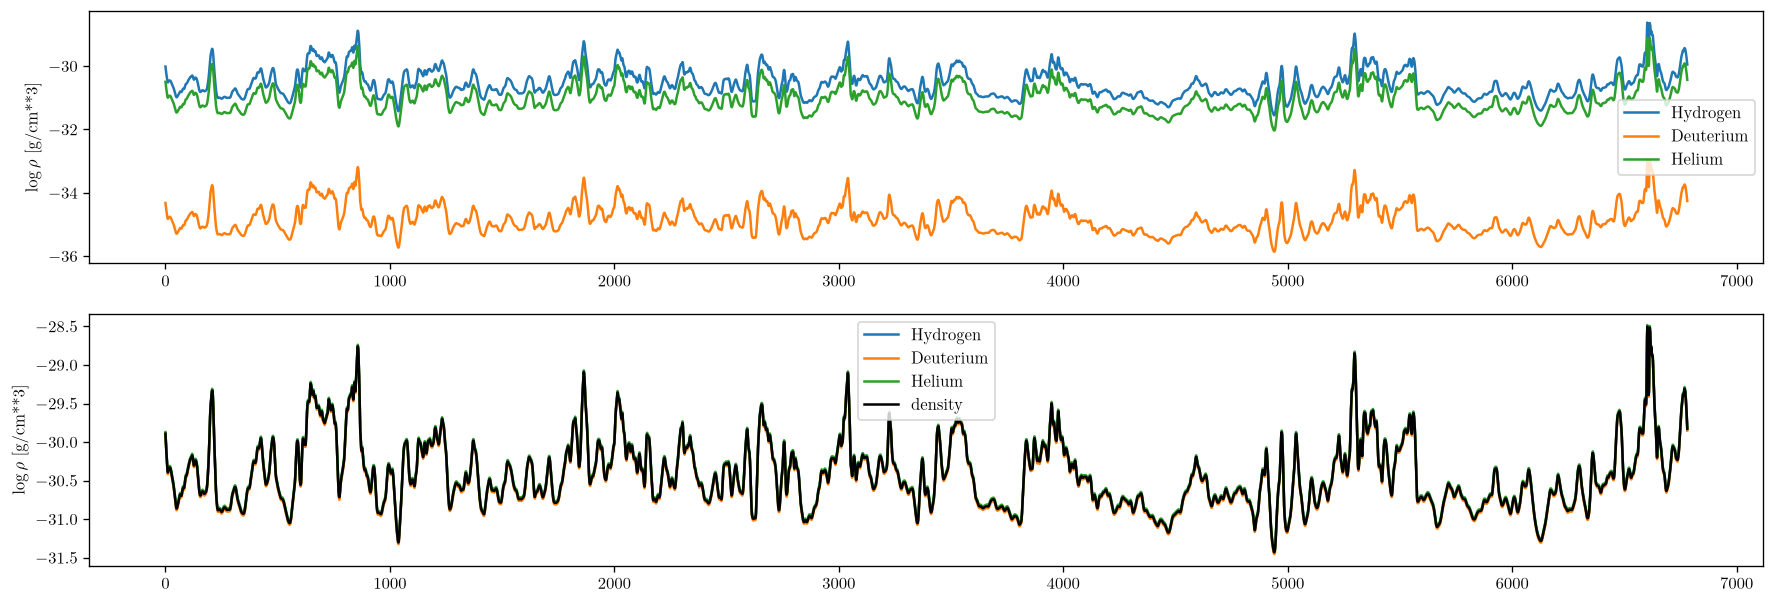

In [25]:
# these are the assumed element abundances by mass
X_H  = 0.752    # Hydrogen 
X_He = 0.248    # Helium
X_D  = 3.7e-5   # Deuterium
fractions = [X_H, X_D, X_He]
elements  = ['Hydrogen', 'Deuterium', 'Helium']
offsets   = [1.0, 0.95, 1.05] # small off set to avoid that different elements totally overlap

# plot the element density along the sight line
fig, ax = plt.subplots(2, 1, figsize=(18, 6), dpi=120)

for element in elements:
    ax[0].plot(vel_kms, np.log10(projected_LOS['Element-weighted'][element]['Densities']['Value'].to('g/cm**3')), label=element)

ax[0].set_ylabel(r'$\log\rho$ [g/cm**3]')
ax[0].legend()

# check the scaling - normalise all element abundances to the total mass dnesity - all coloured lines shpoulkd all ontop of the black total baryon density line
for element, fraction, offset in zip(elements, fractions, offsets):
    ax[1].plot(vel_kms, np.log10(projected_LOS['Element-weighted'][element]['Densities']['Value'].to('g/cm**3') * offset / fraction), label=element)
    
ax[1].plot(vel_kms, np.log10(projected_LOS['Mass-weighted']['Densities']['Value'].to('g/cm**3')),color='black', label='density')
ax[1].legend()
ax[1].set_ylabel(r'$\log\rho$ [g/cm**3]')
fig.show()

## Compute the optical depth

In [26]:
# compute the optical depth
from specwizard import ComputeOpticaldepth
cspec                = ComputeOpticaldepth(Wizard)
opticaldepth         = cspec.MakeAllOpticaldepth(projected_LOS)

## Plot the spectra

The upper panel shows the optical depth for three ions.

These are repated in the lower panel, but the D I abundance (by number) is scaled to that of hydrogen.

Notice that the D I lines are narrower than the H I lines, because the mass of D is twice that of H.

The He II lines are even narrower.


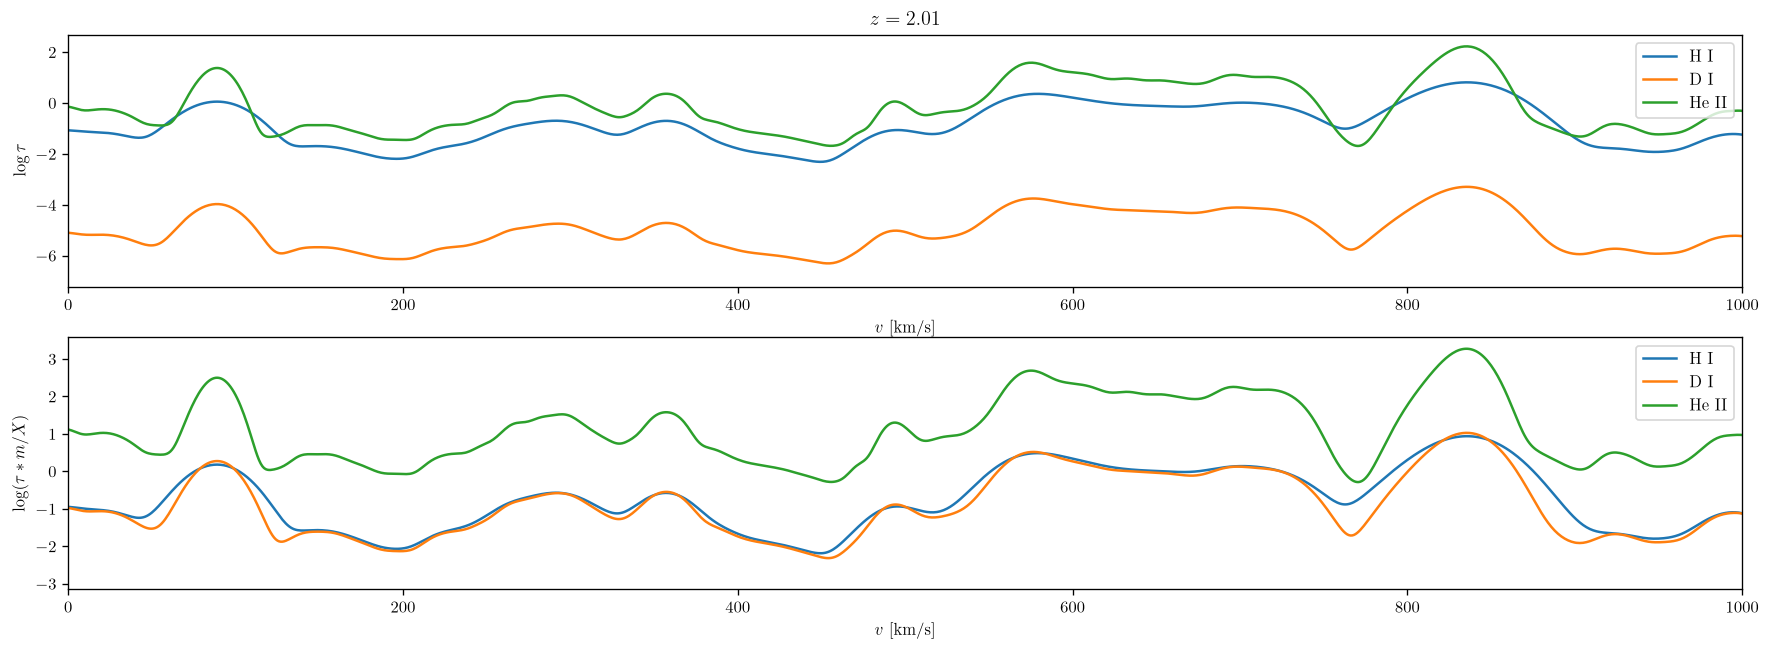

In [27]:
# plot the spectra
fig, ax = plt.subplots(2, 1, figsize=(18, 6), dpi=120)


z = snapshot.header['Cosmo']['Redshift']
ax[0].set_title(r'$z={0:1.2f}$'.format(z))

ions = [('Hydrogen', 'H I'), ('Deuterium', 'D I'), ('Helium', 'He II')]
fractions = [X_H, X_D, X_He]
masses    = [1.008, 2.014101777844, 4.002602]
offsets   = [1.0, 0.9, 1.1]

for ion, mass, fraction, offset in zip(ions, masses, fractions, offsets):
    element, ion_state = ion
    ax[0].plot(vel_kms, np.log10(opticaldepth[ion]['Optical depths']['Value']) * offset, label=ion_state)
    ax[1].plot(vel_kms, np.log10(opticaldepth[ion]['Optical depths']['Value'] * offset * mass / fraction), label=ion_state)

for i in np.arange(2):
    ax[i].legend()
    ax[i].set_xlim(0, 1000)
    
    ax[i].set_xlabel(r'$v$ [km/s]')
ax[0].set_ylabel(r'$\log\tau$')
ax[1].set_ylabel(r'$\log(\tau * m/X)$')

fig.show()